# 02 · Quantization-aware training with HGQ2 + hls4ml conversion

Train the jet tagger with **HGQ2** (high-granularity quantization: every weight and activation learns its own bit width),
convert it with **hls4ml** for the Basys 3 FPGA (`xc7a35tcpg236-1`, 100 MHz) and check that the C++ model is bit-exact with the Keras model.

* Float reference: `01_baseline_float.ipynb` (77.1 % test accuracy)
* Same data split as notebook 01 (same seed, stratified 80/20)
* Output layer returns **logits** (no softmax): the trigger only needs the arg-max / scores, and softmax is expensive in hardware
* `BETA` controls the accuracy ↔ FPGA-resource trade-off (EBOPs ≈ resource estimate)

## 1. Install (if Colab asks to restart the session, restart and continue from cell 2)

In [ ]:
!pip install -q HGQ2 "hls4ml>=1.3"

## 2. Imports and paths

In [ ]:
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'

import numpy as np
import keras
import hls4ml
from hgq.layers import QDense
from hgq.config import LayerConfigScope, QuantizerConfigScope
from hgq.utils.sugar import FreeEBOPs
from hgq.utils import trace_minmax

from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/basys3-l1-trigger/ml'
os.makedirs(OUT, exist_ok=True)

SEED = 42
keras.utils.set_random_seed(SEED)
print('keras', keras.__version__, '| hls4ml', hls4ml.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
keras 3.15.1 | hls4ml 1.3.0


## 3. Data (identical preprocessing to notebook 01)

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

data = fetch_openml(data_id=42468, parser='auto')
X = data.data.to_numpy(dtype=np.float32)
le = LabelEncoder()
y_int = le.fit_transform(data.target)
y = keras.utils.to_categorical(y_int, num_classes=5)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y_int)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train).astype(np.float32)
X_test_s  = scaler.transform(X_test).astype(np.float32)

# sanity check: same scaler as notebook 01
ref = np.load(f'{OUT}/scaler.npz', allow_pickle=True)
assert np.allclose(ref['mean'], scaler.mean_) and np.allclose(ref['scale'], scaler.scale_)
print('classes:', list(le.classes_), '| train', X_train_s.shape, '| test', X_test_s.shape)

classes: ['g', 'q', 't', 'w', 'z'] | train (664000, 16) | test (166000, 16)


## 4. Quantized model

* `kbi` quantizers for weights (keep sign, bits, integer bits), saturating
* `kif` quantizers for activations ("datalane"), wrap-around overflow; integer bits are fixed later with `trace_minmax`
* `BETA` is the knob: larger → fewer bits / fewer resources, lower accuracy

In [ ]:
BETA = 1e-5

with (
    QuantizerConfigScope(q_type='kbi', place='weight',   overflow_mode='SAT_SYM', round_mode='RND'),
    QuantizerConfigScope(q_type='kif', place='datalane', overflow_mode='WRAP',    round_mode='RND'),
    LayerConfigScope(enable_ebops=True, beta0=BETA),
):
    model = keras.Sequential([
        keras.layers.Input(shape=(16,)),
        QDense(64, activation='relu', name='fc1'),
        QDense(32, activation='relu', name='fc2'),
        QDense(32, activation='relu', name='fc3'),
        QDense(5, name='output'),             # logits
    ])

EPOCHS = 100
steps = int(np.ceil(0.75 * len(X_train_s) / 1024)) * EPOCHS
model.compile(
    optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(3e-3, steps)),
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fc1 (QDense)                    │ (None, 64)             │         4,404 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (QDense)                    │ (None, 32)             │         8,516 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc3 (QDense)                    │ (None, 32)             │         4,324 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (QDense)                 │ (None, 5)              │           760 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,004 (57.05 KB)

 Trainable params: 13,178 (51.48 KB)

 Non-trainable params: 4,826 (5.57 KB)

## 5. Train (~15–25 min on CPU). Watch the `ebops` column: it should go down while accuracy stays close to the float model.

In [ ]:
ckpt = f'{OUT}/hgq_beta{BETA:.0e}.keras'
history = model.fit(
    X_train_s, y_train, validation_split=0.25,
    epochs=EPOCHS, batch_size=1024, verbose=2,
    callbacks=[
        FreeEBOPs(),
       keras.callbacks.ModelCheckpoint(ckpt),   # her epoch'ta üzerine yaz → son epoch kalır
    ],
)
model = keras.models.load_model(ckpt)   # last epoch

Epoch 1/100
487/487 - 11s - 23ms/step - accuracy: 0.7149 - loss: 3.1589 - val_accuracy: 0.7481 - val_loss: 0.7124 - ebops: 210839.0000
Epoch 2/100
487/487 - 6s - 13ms/step - accuracy: 0.7484 - loss: 2.2958 - val_accuracy: 0.7476 - val_loss: 0.7158 - ebops: 121790.0000
Epoch 3/100
487/487 - 9s - 18ms/step - accuracy: 0.7471 - loss: 1.7995 - val_accuracy: 0.7458 - val_loss: 0.7146 - ebops: 88269.0000
Epoch 4/100
487/487 - 6s - 12ms/step - accuracy: 0.7437 - loss: 1.5089 - val_accuracy: 0.7386 - val_loss: 0.7393 - ebops: 66672.0000
Epoch 5/100
487/487 - 5s - 11ms/step - accuracy: 0.7383 - loss: 1.3290 - val_accuracy: 0.7376 - val_loss: 0.7508 - ebops: 50598.0000
Epoch 6/100
487/487 - 7s - 15ms/step - accuracy: 0.7327 - loss: 1.2151 - val_accuracy: 0.7307 - val_loss: 0.7718 - ebops: 39518.0000
Epoch 7/100
487/487 - 6s - 11ms/step - accuracy: 0.7300 - loss: 1.1296 - val_accuracy: 0.7276 - val_loss: 0.7925 - ebops: 31476.0000
Epoch 8/100
487/487 - 6s - 13ms/step - accuracy: 0.7303 - loss: 1.

## 6. Evaluate and compare with the float baseline

HGQ test accuracy: 0.7538   (float baseline: 0.7713)
  AUC g: 0.9320
  AUC q: 0.8941
  AUC t: 0.9569
  AUC w: 0.9450
  AUC z: 0.9391


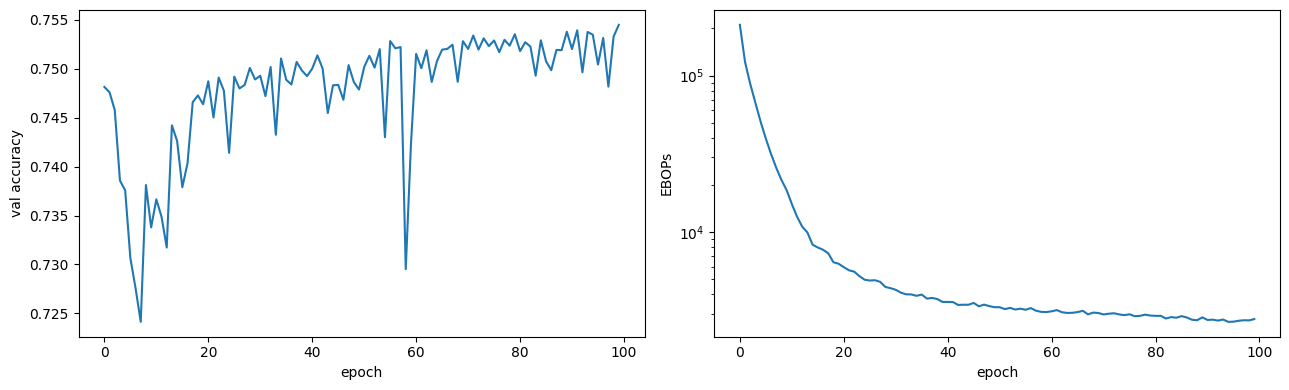

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, roc_auc_score

logits = model.predict(X_test_s, batch_size=4096, verbose=0)
acc = accuracy_score(y_test.argmax(1), logits.argmax(1))
aucs = roc_auc_score(y_test, keras.ops.softmax(logits).numpy(), average=None)
print(f'HGQ test accuracy: {acc:.4f}   (float baseline: 0.7713)')
for c, a in zip(le.classes_, aucs):
    print(f'  AUC {c}: {a:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history.history['val_accuracy']); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('val accuracy')
ax[1].plot(history.history['ebops']); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('EBOPs'); ax[1].set_yscale('log')
plt.tight_layout(); plt.savefig(f'{OUT}/hgq_beta{BETA:.0e}.png', dpi=150); plt.show()

## 7. Fix integer bits on the training data, then convert with hls4ml

`trace_minmax` records the min/max of every activation so the wrap-around quantizers get enough integer bits.
Remember the long tails after standardization (up to ~9σ): values outside the traced range would wrap.

In [ ]:
trace_minmax(model, X_train_s, batch_size=8192, verbose=True)

hls_model = hls4ml.converters.convert_from_keras_model(
    model,
    output_dir='/content/hls4ml_prj_jet',
    backend='Vitis',
    io_type='io_parallel',
    part='xc7a35tcpg236-1',
    clock_period=10,
)
hls_model.compile()   # builds the C++ model for bit-accurate simulation

fc1   : 990
fc2   : 921
fc3   : 540
output: 475
Total: 2926


## 8. Bit-exactness check: Keras (HGQ) vs. hls4ml C++ model

In [ ]:
keras_out = model.predict(X_test_s, batch_size=4096, verbose=0)
hls_out = np.asarray(hls_model.predict(np.ascontiguousarray(X_test_s))).reshape(keras_out.shape)

print('max |difference|     :', np.abs(keras_out - hls_out).max())
print('outputs not identical:', np.mean(keras_out != hls_out))
print('arg-max agreement    :', np.mean(keras_out.argmax(1) == hls_out.argmax(1)))
print('hls4ml test accuracy :', accuracy_score(y_test.argmax(1), hls_out.argmax(1)))

max |difference|     : 0.0
outputs not identical: 0.0
arg-max agreement    : 1.0
hls4ml test accuracy : 0.7538192771084338


## 9. Save the HLS project to Drive (for Vitis HLS synthesis on the lab PC)

In [ ]:
import shutil
zip_path = shutil.make_archive(f'{OUT}/hls4ml_prj_jet_beta{BETA:.0e}', 'zip', '/content/hls4ml_prj_jet')
print('saved:', zip_path)

saved: /content/drive/MyDrive/basys3-l1-trigger/ml/hls4ml_prj_jet_beta1e-05.zip
